# Реальные данные с одним исходным предиктором

Разведочная проверка замены Yacht; основной отчёт не изменён.
Два содержательных столбца означают **один предиктор x и один отклик y**.
Отсутствие других столбцов снимает вопрос об их добавочной пользе внутри этого файла,
но не доказывает, что в природе нет других влияющих факторов.

| Набор | Объём | Предиктор → отклик | Происхождение |
|---|---:|---|---|
| R pressure | 19 | температура → давление паров ртути | справочные физические данные CRC Handbook (1973) |
| NIST Chwirut1 | 214 | расстояние в металле → ультразвуковой отклик | реальные экспериментальные наблюдения NIST |

[Описание pressure](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/pressure.html),
[CSV pressure](https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/pressure.csv),
[оригинал Chwirut1](https://www.itl.nist.gov/div898/strd/nls/data/LINKS/DATA/Chwirut1.dat).
Служебный номер строки pressure не является признаком и не перенесён в CSV.
В Chwirut1 сохранены все 214 строк, включая повторные измерения; значения не изменены.
Единицы расстояния и отклика в файле NIST не уточнены — не приписываем им выдуманные единицы.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneOut, GroupKFold, GroupShuffleSplit

BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GREEN, RED = '#2769A3', '#007F73', '#C94A3D'
if 'render' not in globals():
    def render(fig, filename):
        plt.show()
        plt.close(fig)
pressure = pd.read_csv(BASE / 'data/pressure_mercury.csv')
chwirut = pd.read_csv(BASE / 'data/chwirut1.csv')
assert pressure.shape == (19, 2) and chwirut.shape == (214, 2)
assert not pressure.isna().any().any() and not chwirut.isna().any().any()
temperature = pressure.temperature_c.to_numpy()
p = pressure.pressure_mm_hg.to_numpy()
assert (p > 0).all()

def pressure_basis(temp, logged):
    z = 1 / (np.asarray(temp) + 273.15) if logged else np.asarray(temp)
    return np.column_stack([np.ones(len(z)), z])

def pressure_fit(temp, response, logged=True, clean=False):
    X = pressure_basis(temp, logged)
    z = np.log(response) if logged else np.asarray(response)
    beta = np.linalg.lstsq(X, z, rcond=None)[0]
    keep = np.ones(len(z), bool)
    if clean:
        e = z - X @ beta
        median = np.median(e)
        scale = max(1.4826 * np.median(np.abs(e - median)), 1e-12)
        keep = np.abs(e - median) <= 3.5 * scale
        beta = np.linalg.lstsq(X[keep], z[keep], rcond=None)[0]
    e = z[keep] - X[keep] @ beta
    df = keep.sum() - 2
    cov = (e @ e / df) * np.linalg.inv(X[keep].T @ X[keep])
    return {'beta': beta, 'keep': keep, 'cov': cov, 'df': df,
            'smear': float(np.exp(e).mean()) if logged else 1., 'logged': logged}

def pressure_predict(fit, temp):
    mu = pressure_basis(temp, fit['logged']) @ fit['beta']
    return np.exp(mu) * fit['smear'] if fit['logged'] else mu

pressure_specs = {'Прямая': (False, False),
                  'ln P от 1/T': (True, False),
                  'ln P от 1/T, очистка': (True, True)}
pressure_models, pressure_oof, pressure_scores = {}, {}, {}
for name, (logged, clean) in pressure_specs.items():
    fitted = pressure_fit(temperature, p, logged, clean)
    pred = np.empty(len(p))
    for tr, va in LeaveOneOut().split(temperature):
        fold = pressure_fit(temperature[tr], p[tr], logged, clean)
        pred[va] = pressure_predict(fold, temperature[va])
    pressure_models[name], pressure_oof[name] = fitted, pred
    pressure_scores[name] = {'loo_mae': float(mean_absolute_error(p, pred)),
                             'loo_rmse': float(mean_squared_error(p, pred)**.5),
                             'loo_r2': float(r2_score(p, pred)),
                             'flagged_temperature_c': temperature[~fitted['keep']].tolist()}
fit = pressure_models['ln P от 1/T']

## 1. pressure: простая и сильная линеаризация

Используем температуру в кельвинах: T = t°C + 273.15.
Преобразование — **Z = 1/T, U = ln P**, затем обычная регрессия U = a + bZ.
Это эмпирическое приближение; оно не объявляется точным законом на любой температуре.
На исходной шкале для среднего прогноза применена поправка smearing,
оценённая только по обучающим остаткам.

Проверка leave-one-out: каждую из 19 точек по очереди исключаем, обучаемся на остальных
и прогнозируем исключённую. Очистка также повторяется только на обучающей части
каждого шага. Это оценка на этой небольшой справочной таблице, не независимый
лабораторный эксперимент. На крайних температурах один из шагов требует экстраполяции.

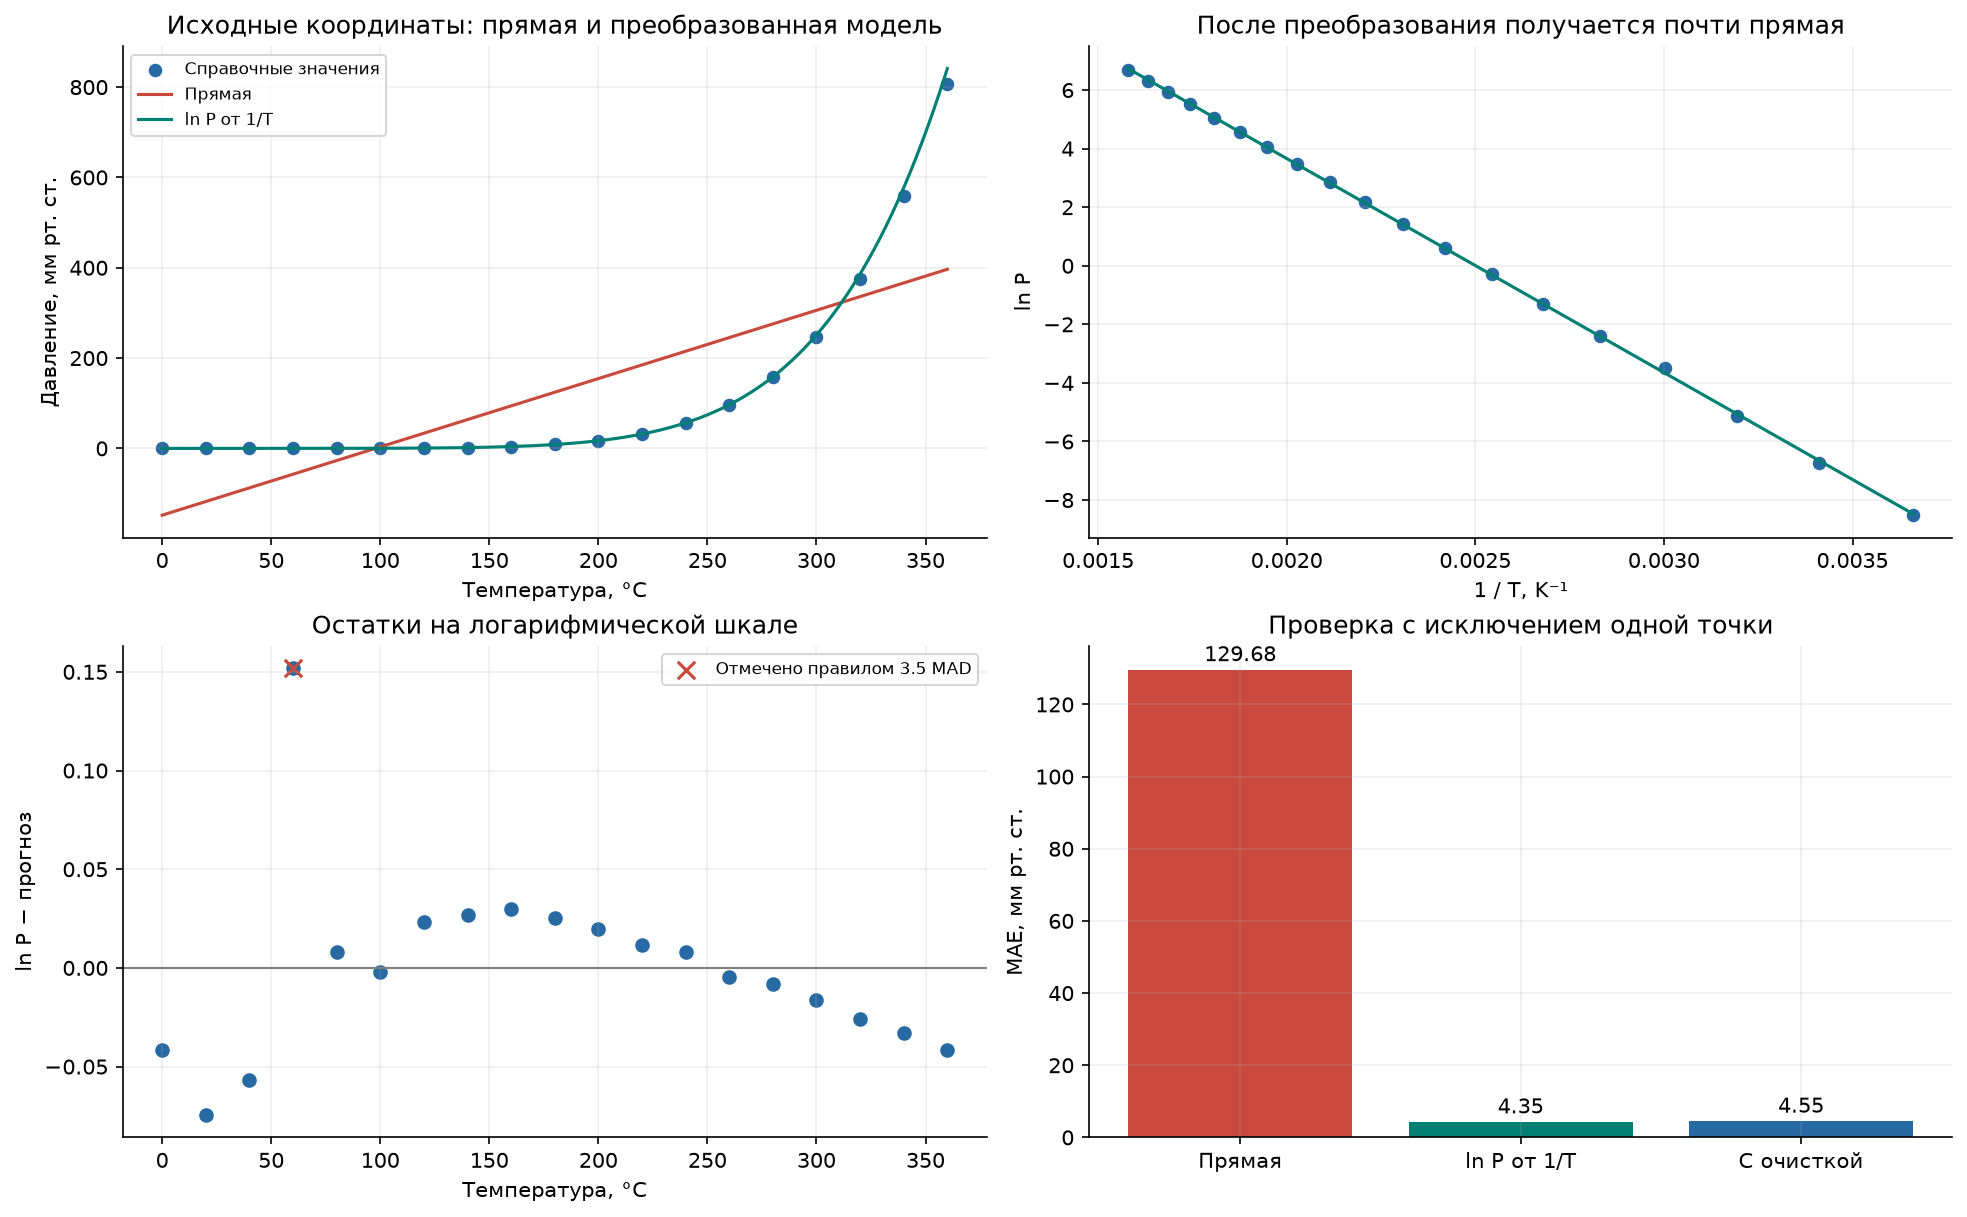

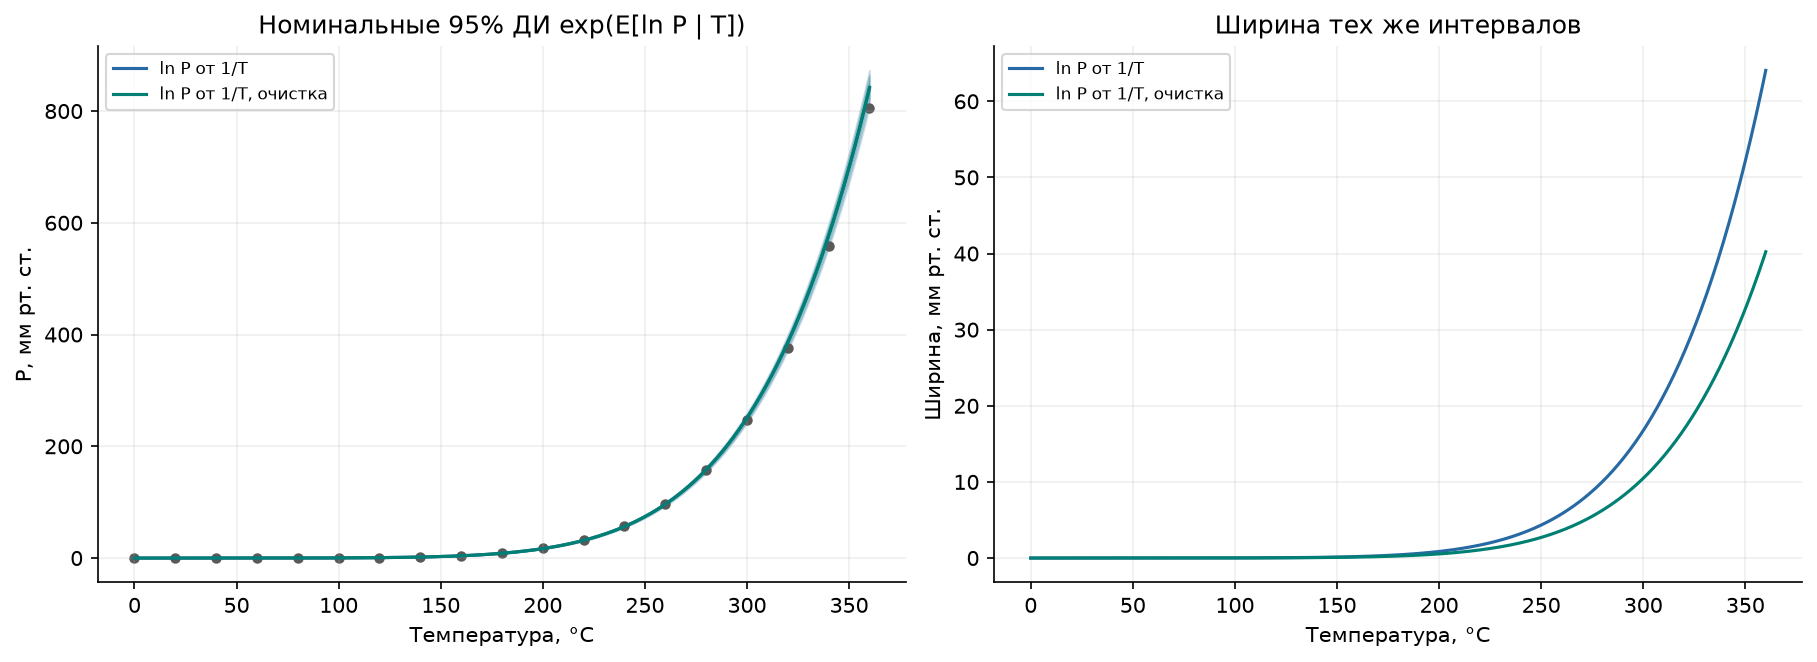

In [2]:
grid = np.linspace(0, 360, 400)
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
axes[0, 0].scatter(temperature, p, c=BLUE, s=30, label='Справочные значения')
for name, color in [('Прямая', RED), ('ln P от 1/T', GREEN)]:
    axes[0, 0].plot(grid, pressure_predict(pressure_models[name], grid), color=color, label=name)
axes[0, 0].set(title='Исходные координаты: прямая и преобразованная модель',
               xlabel='Температура, °C', ylabel='Давление, мм рт. ст.')
axes[0, 0].legend(fontsize=8)
z = 1 / (temperature + 273.15)
zg = np.linspace(z.min(), z.max(), 300)
axes[0, 1].scatter(z, np.log(p), c=BLUE, s=30)
axes[0, 1].plot(zg, fit['beta'][0] + fit['beta'][1] * zg, color=GREEN)
axes[0, 1].set(title='После преобразования получается почти прямая',
               xlabel='1 / T, K⁻¹', ylabel='ln P')
e = np.log(p) - pressure_basis(temperature, True) @ fit['beta']
flag = ~pressure_models['ln P от 1/T, очистка']['keep']
axes[1, 0].scatter(temperature, e, c=BLUE)
axes[1, 0].scatter(temperature[flag], e[flag], c=RED, marker='x', s=70, label='Отмечено правилом 3.5 MAD')
axes[1, 0].axhline(0, c='.5', lw=1)
axes[1, 0].set(title='Остатки на логарифмической шкале', xlabel='Температура, °C', ylabel='ln P − прогноз')
axes[1, 0].legend(fontsize=8)
names = list(pressure_scores)
vals = [pressure_scores[name]['loo_mae'] for name in names]
axes[1, 1].bar(range(3), vals, color=[RED, GREEN, BLUE])
for i, val in enumerate(vals):
    axes[1, 1].annotate(f'{val:.2f}', (i, val), xytext=(0, 4), textcoords='offset points', ha='center')
axes[1, 1].set(xticks=range(3), xticklabels=['Прямая', 'ln P от 1/T', 'С очисткой'],
               title='Проверка с исключением одной точки', ylabel='MAE, мм рт. ст.')
for ax in axes.ravel(): ax.grid(alpha=.2)
render(fig, 'pressure_linearization.png')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
Xg = pressure_basis(grid, True)
for name, color in [('ln P от 1/T', BLUE), ('ln P от 1/T, очистка', GREEN)]:
    model = pressure_models[name]
    mu = Xg @ model['beta']
    half = t.ppf(.975, model['df']) * np.sqrt(np.einsum('ij,jk,ik->i', Xg, model['cov'], Xg))
    axes[0].plot(grid, np.exp(mu), c=color, label=name)
    axes[0].fill_between(grid, np.exp(mu-half), np.exp(mu+half), color=color, alpha=.2)
    axes[1].plot(grid, np.exp(mu+half)-np.exp(mu-half), c=color, label=name)
axes[0].scatter(temperature, p, s=16, c='.35')
axes[0].set(title='Номинальные 95% ДИ exp(E[ln P | T])', xlabel='Температура, °C', ylabel='P, мм рт. ст.')
axes[1].set(title='Ширина тех же интервалов', xlabel='Температура, °C', ylabel='Ширина, мм рт. ст.')
for ax in axes: ax.grid(alpha=.2); ax.legend(fontsize=8)
render(fig, 'pressure_cleaning_intervals.png')

Получено уравнение **ln P = 18.273754 -7306.653792/T**.
Средний прогноз в исходной шкале: P̂ ≈ 1.001099 · exp(18.273754 -7306.653792/T).
Диапазон таблицы: **0–360 °C**; перенос за его пределы не проверен.

LOO-MAE прямой — **129.680**, преобразованной модели —
**4.352 мм рт. ст.**;
LOO-R² в исходной шкале — **0.99748**.
R² не является долей правильно угаданных значений.

Правило 3.5 MAD отметило температуру **[60] °C**;
LOO-MAE с очисткой — **4.553**.
Отметка не доказывает ошибку справочника: возможны округление и неточность формы модели.
Исходную строку сохраняем; исключение показано как анализ чувствительности.

**Ограничения:** всего 19 справочных точек; источник R не даёт повторных измерений и
их погрешностей. Интервалы выше предполагают независимые нормальные остатки с одинаковой
дисперсией после логарифмирования. Это условные интервалы регрессионной модели для
геометрического среднего, а не метрологическая неопределённость давления и не прогнозные
интервалы отдельного измерения. Выбор отмеченной строки в интервалах не переоценивается.
Малую относительную ошибку на всём диапазоне один высокий R² также не гарантирует.

## 2. Chwirut1: больше экспериментальных измерений, но сложнее формула

NIST прямо помечает набор как **Observed Data**: 214 наблюдений, один предиктор
и один отклик. На 22 расстояниях есть повторные измерения; это не 214 разных расстояний.
Файл не содержит номеров экспериментальных серий, поэтому независимость серий проверить нельзя.

Показываем все исследованные семейства, включая неудачные.
Разделение GroupShuffleSplit(seed=42): разные значения расстояния целиком попадают
в обучение или в проверку. Внутри обучения — GroupKFold по расстоянию.
Среди проверочных значений есть 0.5, ниже минимума обучения 0.75;
поэтому часть этой проверки оценивает экстраполяцию.
Сравнение разведочное: модели изучались при поиске набора, отложенная часть
не является окончательным независимым подтверждением выбранной формулы.

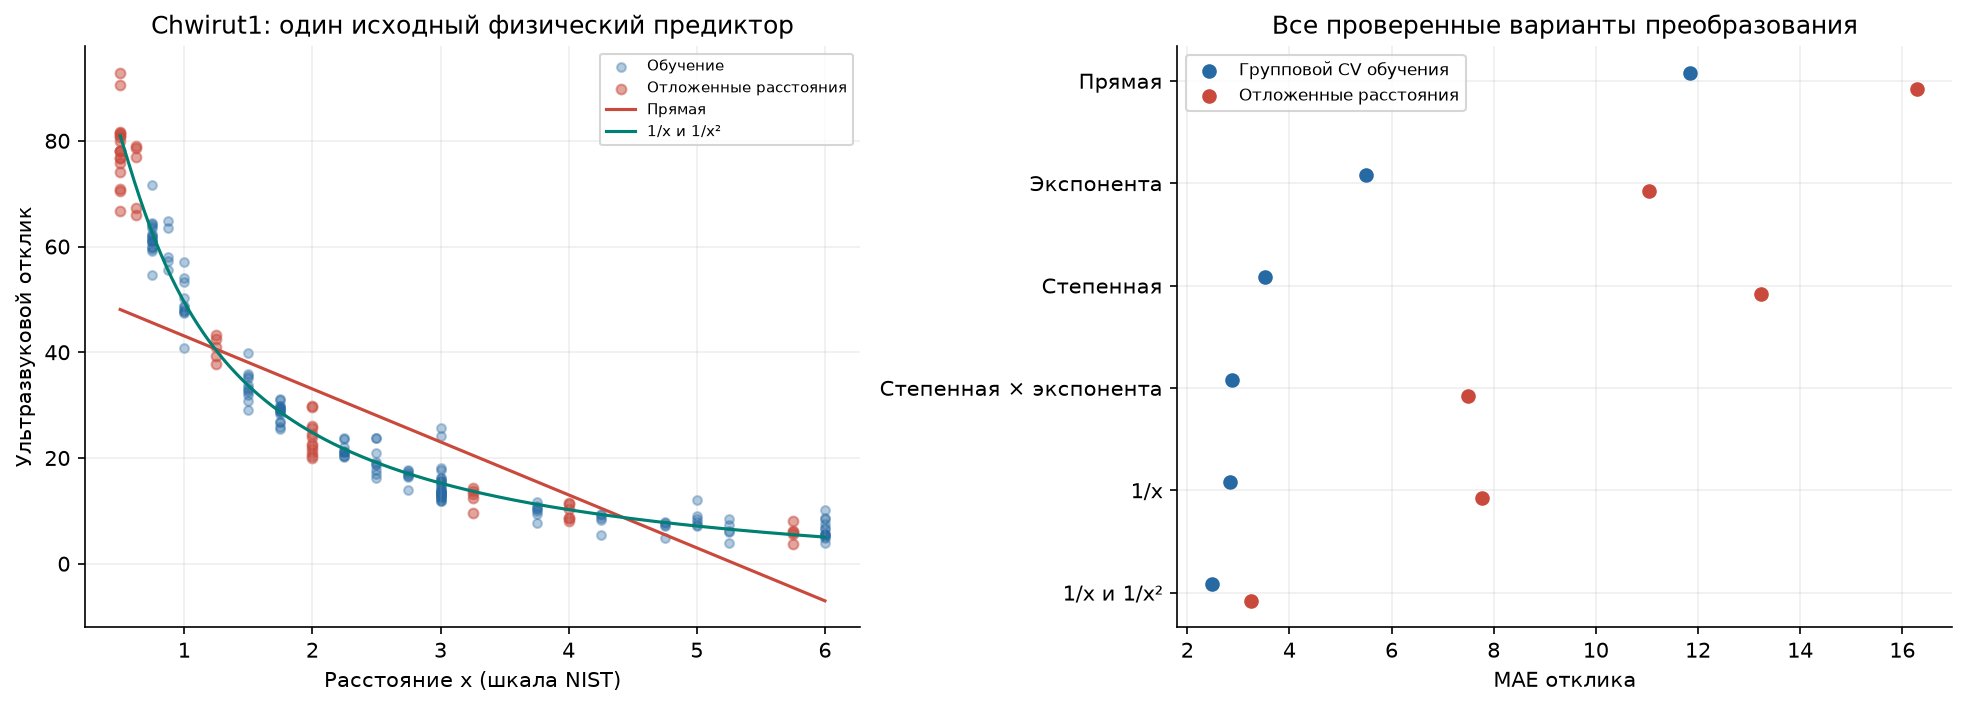

In [3]:
x = chwirut.distance.to_numpy()
y = chwirut.ultrasonic_response.to_numpy()
assert (x > 0).all() and (y > 0).all()
reference = np.exp(-.19027818370*x) / (.0061314004477 + .010530908399*x)
assert np.isclose(((y-reference)**2).sum(), 2384.4771393, rtol=1e-8)
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=.3, random_state=42).split(x, groups=x))
ch_specs = ['Прямая', 'Экспонента', 'Степенная', 'Степенная × экспонента', '1/x', '1/x и 1/x²']

def ch_basis(x, name):
    if name == 'Степенная': return np.column_stack([np.ones(len(x)), np.log(x)])
    if name == 'Степенная × экспонента': return np.column_stack([np.ones(len(x)), np.log(x), x])
    if name == '1/x': return np.column_stack([np.ones(len(x)), 1/x])
    if name == '1/x и 1/x²': return np.column_stack([np.ones(len(x)), 1/x, 1/x**2])
    return np.column_stack([np.ones(len(x)), x])

def ch_predict(training, validation, name):
    logged = name in ['Экспонента', 'Степенная', 'Степенная × экспонента']
    z = np.log(y[training]) if logged else y[training]
    X = ch_basis(x[training], name)
    beta = np.linalg.lstsq(X, z, rcond=None)[0]
    p = ch_basis(x[validation], name) @ beta
    smear = np.exp(z-X@beta).mean() if logged else 1.
    return (np.exp(p)*smear if logged else p), beta

ch_scores = {}
for name in ch_specs:
    pred, beta = ch_predict(tr, te, name)
    oof = np.empty(len(tr))
    for a, v in GroupKFold(n_splits=5).split(tr, groups=x[tr]):
        oof[v] = ch_predict(tr[a], tr[v], name)[0]
    ch_scores[name] = {'beta': beta.tolist(), 'cv_mae': float(mean_absolute_error(y[tr], oof)),
                       'test_mae': float(mean_absolute_error(y[te], pred)),
                       'test_r2': float(r2_score(y[te], pred))}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout='constrained')
axes[0].scatter(x[tr], y[tr], c=BLUE, alpha=.35, s=18, label='Обучение')
axes[0].scatter(x[te], y[te], c=RED, alpha=.5, s=22, label='Отложенные расстояния')
g = np.linspace(x.min(), x.max(), 400)
for name, color in [('Прямая', RED), ('1/x и 1/x²', GREEN)]:
    axes[0].plot(g, ch_basis(g, name)@np.asarray(ch_scores[name]['beta']), c=color, label=name)
axes[0].set(title='Chwirut1: один исходный физический предиктор', xlabel='Расстояние x (шкала NIST)', ylabel='Ультразвуковой отклик')
axes[0].legend(fontsize=7)
pos = np.arange(len(ch_specs))
axes[1].scatter([ch_scores[n]['cv_mae'] for n in ch_specs], pos-.08, c=BLUE, label='Групповой CV обучения')
axes[1].scatter([ch_scores[n]['test_mae'] for n in ch_specs], pos+.08, c=RED, label='Отложенные расстояния')
axes[1].set(yticks=pos, yticklabels=ch_specs, xlabel='MAE отклика', title='Все проверенные варианты преобразования')
axes[1].invert_yaxis(); axes[1].legend(fontsize=8)
for ax in axes: ax.grid(alpha=.2)
render(fig, 'chwirut1_comparison.png')

Для линейной по коэффициентам модели с признаками 1/x и 1/x²:

**ŷ = -5.84183 +67.24555/x -11.91475/x².**

MAE на отложенных расстояниях: **16.293 → 3.247**,
R² преобразованной модели — **0.9770**.
Это эмпирическая аппроксимация, отличающаяся от исходной нелинейной формулы NIST.
Исходный предиктор остаётся один, но базисных членов два;
это не демонстрация превращения ln y от ln x в одну прямую.
Диапазон исходных данных 0.5–6; область обучения текущего разбиения 0.75–6.
Для этой альтернативы полная проверка выбросов и доверительных интервалов ещё не выполнена.

**Рекомендация по выбору:** pressure проще всего объяснить как явную линеаризацию
с одним предиктором. Chwirut1 даёт больше реальных экспериментальных наблюдений,
но требует более сложной формы зависимости. Оба набора отсутствуют среди названий
в локальном списке 59 видимых файлов преподавателя; это не полная проверка его каталога.
Ни один вариант не объявляется автоматически согласованным с преподавателем.

## Если оставить Yacht

Для Yacht корректна формулировка: «Число Фруда даёт около 99.2% суммарного снижения MSE
относительно константы в выбранном Shapley-разложении; геометрия дополнительно
уменьшает ошибку модели с одним F». Это доля улучшения выбранного семейства моделей,
а не процент правильных ответов, не физическая доля сопротивления и не доказательство
бесполезности остальных параметров. R², долю Шепли и улучшение ошибки после добавления
геометрии следует приводить отдельно, поскольку у них разные знаменатели.